# 常用的损失函数

## 损失函数的作用
- 评估模型的预测精度
- 为模型的优化指明方向

## 经验误差
- 训练集上的误差

## 泛化误差
- 测试集上的误差

## 欠拟合 与 过拟合
- 欠拟合：模型在训练集上的误差和测试集上的误差都很大
- 过拟合：模型在训练集上的误差很小，但在测试集上的误差很大




In [97]:
# 演示欠拟合 和 过拟合
# [3,-3]
import numpy as np
from  matplotlib import pyplot as plt
X  = np.linspace(-3,3,300).reshape(-1,1)
X

array([[-3.        ],
       [-2.97993311],
       [-2.95986622],
       [-2.93979933],
       [-2.91973244],
       [-2.89966555],
       [-2.87959866],
       [-2.85953177],
       [-2.83946488],
       [-2.81939799],
       [-2.7993311 ],
       [-2.77926421],
       [-2.75919732],
       [-2.73913043],
       [-2.71906355],
       [-2.69899666],
       [-2.67892977],
       [-2.65886288],
       [-2.63879599],
       [-2.6187291 ],
       [-2.59866221],
       [-2.57859532],
       [-2.55852843],
       [-2.53846154],
       [-2.51839465],
       [-2.49832776],
       [-2.47826087],
       [-2.45819398],
       [-2.43812709],
       [-2.4180602 ],
       [-2.39799331],
       [-2.37792642],
       [-2.35785953],
       [-2.33779264],
       [-2.31772575],
       [-2.29765886],
       [-2.27759197],
       [-2.25752508],
       [-2.23745819],
       [-2.2173913 ],
       [-2.19732441],
       [-2.17725753],
       [-2.15719064],
       [-2.13712375],
       [-2.11705686],
       [-2

In [98]:
# 噪声形状要和 X 一致 (300,1)，否则 (300,1)+(300,) 会广播成 (300,300)
Y =  np.sin(X)  + np.random.uniform(-0.1, 0.1,(300,1))
Y = Y.reshape((-1,1))
Y.shape

(300, 1)

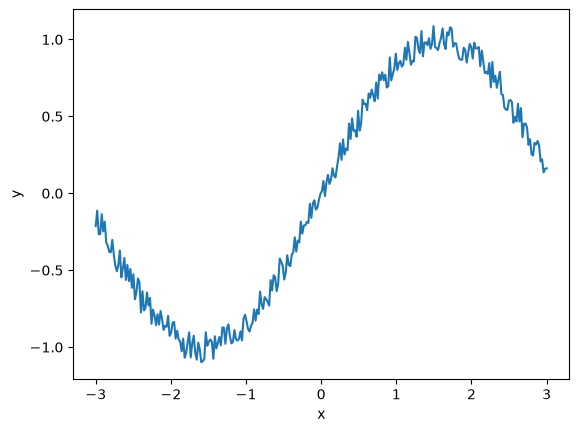

In [99]:
# 画图
plt.figure()
plt.plot(X, Y)
# 设置标题
plt.title = "sin(x)"
plt.xlabel("x")
plt.ylabel("y")
plt.show()

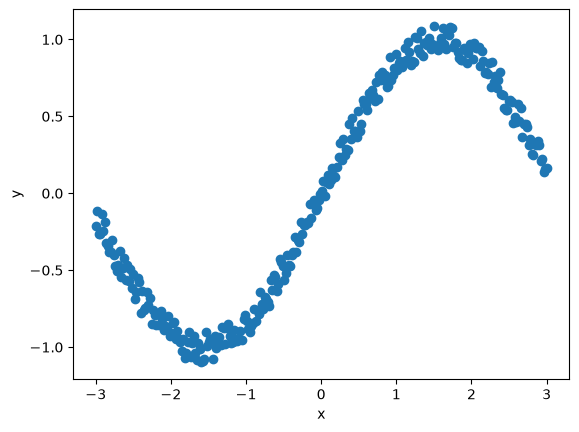

In [100]:
# 绘制散点图
plt.figure()
plt.scatter(X, Y)
plt.title = "sin(x)"
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [101]:
from sklearn.linear_model import LinearRegression # 使用线性回归
# 划分数据集
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((240, 1), (60, 1), (240, 1), (60, 1))

In [102]:
# 创建线性回归模型
model = LinearRegression()
# 训练模型
model.fit(X_train, Y_train)
# 模型的参数
model.coef_, model.intercept_
# .coef_ 系数 .intercept_ 截距

(array([[0.33856777]]), array([-0.00070792]))

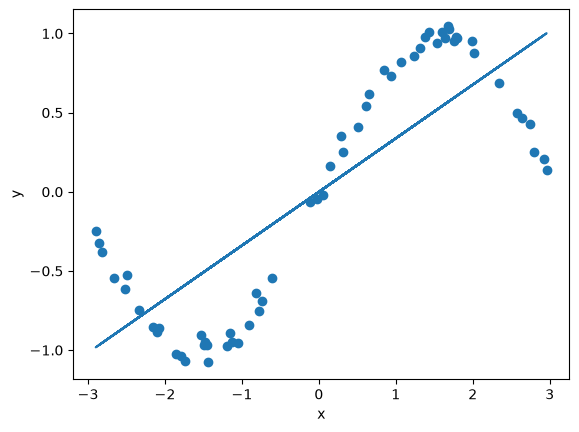

In [103]:
# 绘制预测结果
y_pred = model.predict(X_test)
plt.figure()
plt.scatter(X_test, Y_test)
plt.plot(X_test, y_pred)
# 设置标题
# 设置 x 轴标签
plt.xlabel("x")
# 设置 y 轴标签
plt.ylabel("y")
plt.show()


In [104]:
# 模型评估
# mse 均方误差
from sklearn.metrics import mean_squared_error
test_loss  = mean_squared_error(Y_test, y_pred)
train_loss = mean_squared_error(Y_train, model.predict(X_train))


In [105]:
print(f"欠拟合: 训练误差: {train_loss}, 测试误差: {test_loss}")

欠拟合: 训练误差: 0.1627470090169273, 测试误差: 0.19173333689200062


## 多项式可以增加模型的非线性

In [106]:
# 增加多项式特征
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=10)
X_train_poly = poly.fit_transform(X_train)
print(X_train_poly.shape)
X_test_poly = poly.transform(X_test)


(240, 11)


In [107]:
# 再次训练模型
model_poly = LinearRegression()

model_poly.fit(X_train_poly, Y_train)
model_poly.coef_, model_poly.intercept_


(array([[ 0.00000000e+00,  1.01633415e+00, -4.48383956e-03,
         -1.83382566e-01,  6.55208416e-04,  1.33404044e-02,
          1.18462418e-03, -8.59409530e-04, -2.98087347e-04,
          3.62988092e-05,  1.85348566e-05]]),
 array([-0.00293678]))

In [108]:
# 模型评估
test_loss = mean_squared_error(Y_test, model_poly.predict(X_test_poly))
train_loss = mean_squared_error(Y_train, model_poly.predict(X_train_poly))
print(f"过拟合: 训练误差: {train_loss}, 测试误差: {test_loss}")


过拟合: 训练误差: 0.0032511397590811323, 测试误差: 0.0025758002079256316


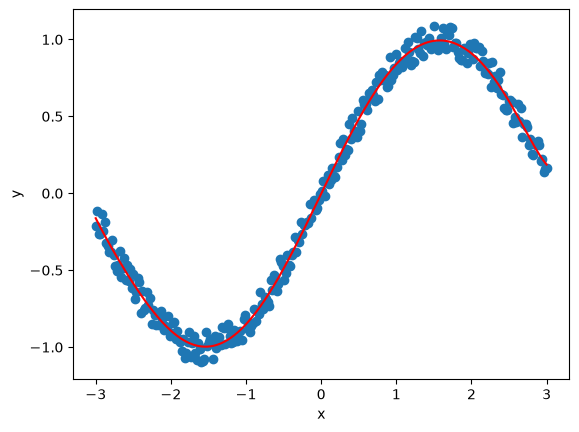

In [109]:
# 绘制预测结果
y_pred_poly = model_poly.predict(poly.transform(X))
plt.figure()
plt.scatter(X, Y)
plt.plot(X, y_pred_poly,color="red")
plt.title="Polynomial Regression"
plt.xlabel("x")
plt.ylabel("y")
plt.show()
